In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import hashlib
import json
from datetime import datetime

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = pd.Series(iris.target, name="species")

df = X.copy()
df["species"] = y

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
print("Missing values:")
print(X.isnull().sum())

print("\nDataset statistics:")
display(X.describe())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Dataset statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Training records: 120
Testing records: 30


In [4]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [5]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

Model Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



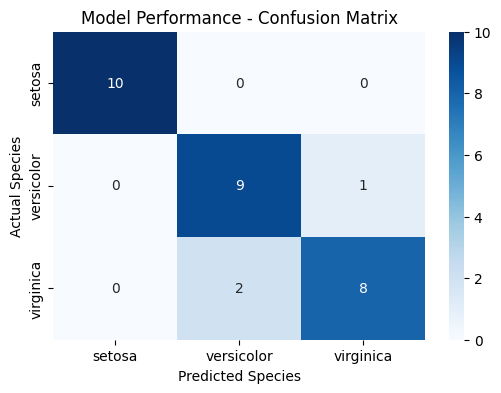

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Model Performance - Confusion Matrix")
plt.show()

In [7]:
model_file = "iris_model.pkl"

joblib.dump(model, model_file)

print("Model saved successfully:", model_file)

Model saved successfully: iris_model.pkl


In [8]:
loaded_model = joblib.load(model_file)

loaded_predictions = loaded_model.predict(X_test)

assert np.array_equal(
    y_pred,
    loaded_predictions
), "Model verification failed!"

print("Saved model loaded successfully.")
print("Model predictions verified.")

Saved model loaded successfully.
Model predictions verified.


In [9]:
start_time = datetime.now()

# Run predictions using the saved model
loaded_model = joblib.load(model_file)
analytics_predictions = loaded_model.predict(X_test)

end_time = datetime.now()

execution_time = (
    end_time - start_time
).total_seconds()

analytics = {
    "model_name": "Random Forest Classifier",
    "dataset": "Iris Dataset",
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "accuracy": round(
        accuracy_score(y_test, analytics_predictions), 4
    ),
    "execution_time_seconds": round(execution_time, 4),
    "model_file": model_file
}

print("MLOps Analytics Report")
print(json.dumps(analytics, indent=4))

MLOps Analytics Report
{
    "model_name": "Random Forest Classifier",
    "dataset": "Iris Dataset",
    "training_records": 120,
    "testing_records": 30,
    "accuracy": 0.9,
    "execution_time_seconds": 0.1141,
    "model_file": "iris_model.pkl"
}


In [10]:
with open("mlops_analytics.json", "w") as f:
    json.dump(analytics, f, indent=4)

print("Analytics report saved successfully!")

Analytics report saved successfully!


In [11]:
# Calculate baseline statistics from training data
baseline_mean = X_train.mean()
baseline_std = X_train.std().replace(0, 1)

# Simulate incoming data
incoming_data = X_test.copy()

# Calculate average feature values
incoming_mean = incoming_data.mean()

# Measure standardized differences
drift_score = (
    (incoming_mean - baseline_mean).abs()
    / baseline_std
)

monitoring_report = pd.DataFrame({
    "Training Mean": baseline_mean,
    "Incoming Mean": incoming_mean,
    "Standardized Difference": drift_score
})

print("Model Monitoring Report")
display(monitoring_report.round(3))

threshold = 0.5

if (drift_score > threshold).any():
    print("ALERT: Potential feature distribution change detected!")
else:
    print("Monitoring Status: No significant feature change detected.")

Model Monitoring Report


,Training Mean,Incoming Mean,Standardized Difference
sepal length (cm),5.842,5.850,0.010
sepal width (cm),3.048,3.093,0.100
petal length (cm),3.770,3.710,0.034
petal width (cm),1.205,1.177,0.037


Monitoring Status: No significant feature change detected.


In [12]:
with open("iris_model.pkl", "rb") as f:
    checksum = hashlib.sha256(f.read()).hexdigest()

print("Model Integrity Check")
print("SHA-256 Checksum:", checksum)
print("Model artifact is available and readable.")

Model Integrity Check
SHA-256 Checksum: f2d5d41df948b058d000bac108d1f7247244d88ce05e90549caccfd1d8f94921
Model artifact is available and readable.


In [13]:
from google.colab import files

files.download("iris_model.pkl")
files.download("mlops_analytics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>